# Integrated Multi-Modal Spatial Biology & Metabolomics Pipeline
### Publication-Quality Analytics & Visualization Suite

This refactored notebook provides a streamlined interface for statistical analysis and visualization of multi-modal tissue datasets (SRS, CODEX, MALDI dual-mode mass spectrometry, collagen SHG morphology, and snRNA-seq).

#### Workflow Highlights:
1. **Glomeruli Analysis Pipeline**: Spatial clustering (DBSCAN on centroids) of Cluster 1 podocytes to identify individual glomeruli, compute glom-level averages, inter-glomerular metabolite correlation heatmaps, and regional compartment comparisons.
2. **Statistical Group Comparisons**: Violin / Box + Strip Plots + Welch's ANOVA & Games-Howell post-hoc tests with significance brackets.
3. **Paired Multi-Feature Bar Charts**: Multi-species bar charts with error bars (Std/SEM) and automated significance stars.
4. **Compact Inset Bar Plots**: Publication-ready transparent figure insets for anatomical overlays.
5. **Correlation Analysis**: Metabolite correlation matrix heatmaps & target metric correlation rank plots.
6. **Spatial Coordinates & Distributions**: Centroid tissue mapping & stacked cell composition charts.
7. **UMAP & Dimensionality Reduction**: Categorical cluster projections & continuous gradient heatmaps.
8. **Dataset Registry & Audit Logger**: Automatic multi-project dataset switching and session audit trail tracking.

In [8]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add repository root and sk_classifier to sys.path

sys.path.insert(0, str(Path.cwd()))
sys.path.insert(0, str(Path.cwd().parent))

# Import unified plotting and statistical toolkit
from ip_plotting import (
    DATASET_REGISTRY,
    DATASET_LOAD_LOG,
    load_project_dataset,
    display_dataset_log,
    UNIT_CLUSTERS,
    CLUSTER_COLORS,
    FTU_MAP,
    FIB_MAP,
    GROUP_ORDER,
    UNIT_ORDER,
    METRIC_GROUPS,
    plot_group_comparisons,
    plot_feature_bars,
    plot_compact_inset,
    plot_correlation_matrix,
    plot_target_correlations,
    plot_spatial_coordinates,
    plot_category_distribution,
    plot_umap_embedding,
    plot_umap_with_region_density_overlay,
    identify_glomeruli_clusters,
    plot_glomeruli_spatial_clusters,
    run_welch_games_howell,
    stars,
    format_p_value
)

# Set global plotting aesthetic
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans', 'Helvetica']
plt.rcParams['axes.edgecolor'] = 'black'
plt.rcParams['axes.linewidth'] = 1.2
print("Setup completed: Toolkit and styling initialized.")

Setup completed: Toolkit and styling initialized.


## 1. Project Dataset Registry & Session Audit Log
Select the active project below (`CODEX_WSI`, `VALLON_D2O_SGLT2I`, `COLLAGEN_PROXIMITY`, or `SNRNA_INTEGRATION`). 
All loaded files are automatically audited and logged with timestamps, file paths, and record dimensions.

In [2]:
# Choose active project to load
ACTIVE_PROJECT = "CODEX_WSI"  # Options: 'CODEX_WSI' | 'VALLON_D2O_SGLT2I' | 'COLLAGEN_PROXIMITY' | 'SNRNA_INTEGRATION'

if ACTIVE_PROJECT == "CODEX_WSI":
    # Load main CODEX cluster and WSI multi-modal quantification dataset
    # Provide fallback relative path if OneDrive path differs
    df = load_project_dataset(
        "CODEX_WSI", 
        "main_output", 
        fallback_path=r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\WSI_data\WSI_data\CODEX_clusters-regions_masks_output_csv-test\output.csv"
    )
elif ACTIVE_PROJECT == "VALLON_D2O_SGLT2I":
    # Load Vallon SGLT2i kidney turnover & SRS metrics
    df_srs = load_project_dataset("VALLON_D2O_SGLT2I", "srs_metrics_csv")
    df_to = load_project_dataset("VALLON_D2O_SGLT2I", "turnover_parquet")
    to_cols = ['Image Name', 'ROI Inst', 'Label', 'Protein_Turnover Mean', 'Lipid_Turnover Mean', 'Lipid_to_Protein Mean', 'Lipid_Unsaturation Mean']
    df = pd.merge(df_srs, df_to[to_cols], on=['Image Name', 'ROI Inst', 'Label'], how='left')

# Display dataset audit log
display_dataset_log()

 Loaded [CODEX_WSI :: main_output] -> 175,528 rows x 71 cols


,Timestamp,Project,Dataset Key,File Path,Rows,Columns,Memory (MB)
0,2026-10-05 18:05:30,CODEX_WSI,main_output,C:\Users\jvill\OneDrive - UC San Diego\integra...,175528,71,146.25


## 2. Data Preprocessing & Anatomical Taxonomy Mapping
Cleans raw outputs, maps clusters to canonical functional units (FTUs), groups metadata, and applies quality-control instance thresholds.

In [3]:
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

# 1. Apply Canonical Taxonomy Mappings
if 'mask_name' in df.columns:
    df['unit'] = df['mask_name'].map(UNIT_CLUSTERS).fillna(df['mask_name'])
    df['FTU'] = df['mask_name'].map(FTU_MAP).fillna(df['mask_name'])

if 'group' in df.columns:
    # Standardize region naming
    df = df.replace({
        'Middle Cortex': 'Outer Cortex',
        'Juxtamedullary Cortex': 'Inner Cortex'
    })
    df['fib'] = df['group'].map(FIB_MAP).fillna(df['group'])


# 2. Calculate Group Representation & Apply Minimum Size Filter
if 'group' in df.columns and 'mask_name' in df.columns:
    unit_sizes = df.groupby('mask_name')['mask_name'].transform('count')
    unit_group_sizes = df.groupby(['group', 'mask_name'])['mask_name'].transform('count')
    df['cluster_group_pct'] = (unit_group_sizes / unit_sizes) * 100
    
    # Filter out clusters with < 5% representation within the unit for clean statistics
    filtered_df = df[df['cluster_group_pct'] >= 5.0].copy()
else:
    filtered_df = df.copy()

# Numerical quantification columns
num_cols = list(filtered_df.select_dtypes(include='number').columns)
exclude_num = ['centroid_y', 'centroid_x', 'cluster_group_pct', 'glom']
val_cols = [col for col in num_cols if col not in exclude_num]

print(f"Data ready for visualization: {filtered_df.shape[0]:,} instances remaining across {len(val_cols)} quantification features.")

# Z-normalization of value columns
z_df = filtered_df[(filtered_df[val_cols] != 0).all(axis=1)].copy()
z_df[val_cols] = z_df.groupby(['tissue_id'])[val_cols].transform(lambda x: (x - x.mean()) / (x.std() + 1e-8))

Data ready for visualization: 172,432 instances remaining across 64 quantification features.


## 3. Dedicated Glomeruli (Cluster 1) Analysis Pipeline
This section provides an end-to-end pipeline for **identifying, profiling, and analyzing individual glomeruli**:
1. **Spatial Density Clustering (`DBSCAN`)**: Groups single-cell podocyte/glomeruli detections (`Cluster1`) by `(centroid_x, centroid_y)` spatial proximity per tissue slide to label individual glomeruli (`glom` $\ge 0$).
2. **Spatial Map of Glomeruli**: Plots segmented glomeruli in 2D tissue coordinate space with numbered ID annotations at each glomerulus geometric center.
3. **Glomerular Instance Aggregation**: Calculates mean molecular/metabolite profiles for each individual glomerulus across tissue sections.
4. **Inter-Glomerular Metabolite Correlations**: Generates correlation matrices and extracts ranked pairwise metabolite interactions.
5. **Regional Glomerular Comparisons (Inner vs. Outer Cortex)**: Evaluates metabolic and lipidomic shifts between juxtamedullary and superficial cortical glomeruli with paired significance bar charts and compact insets.

In [4]:
# Step 1: Spatial Density Clustering of Cluster 1 Instances (DBSCAN on Centroids)
if 'centroid_x' in filtered_df.columns and 'centroid_y' in filtered_df.columns:
    filtered_df = identify_glomeruli_clusters(
        df=filtered_df,
        cluster_name='Cluster1',
        cluster_col='mask_name',
        eps=80,
        min_samples=20,
        x_col='centroid_x',
        y_col='centroid_y',
        tissue_col='tissue_id' if 'tissue_id' in filtered_df.columns else 'group',
        glom_col='glom'
    )
else:
    print("Spatial centroid columns (centroid_x, centroid_y) not found in dataset.")

# Manual reassignment of glom spatial grouping
z_df['glom'] = filtered_df['glom']
filtered_df.loc[filtered_df['glom'] == 12, 'group']='Inner Cortex'
z_df.loc[z_df['glom'] == 12, 'group']='Inner Cortex'

 Identified 37 individual glomeruli across 2 tissue sections (Cluster 'Cluster1').


Saved glomeruli spatial plot to: ./plots/glomeruli_spatial_clusters.png


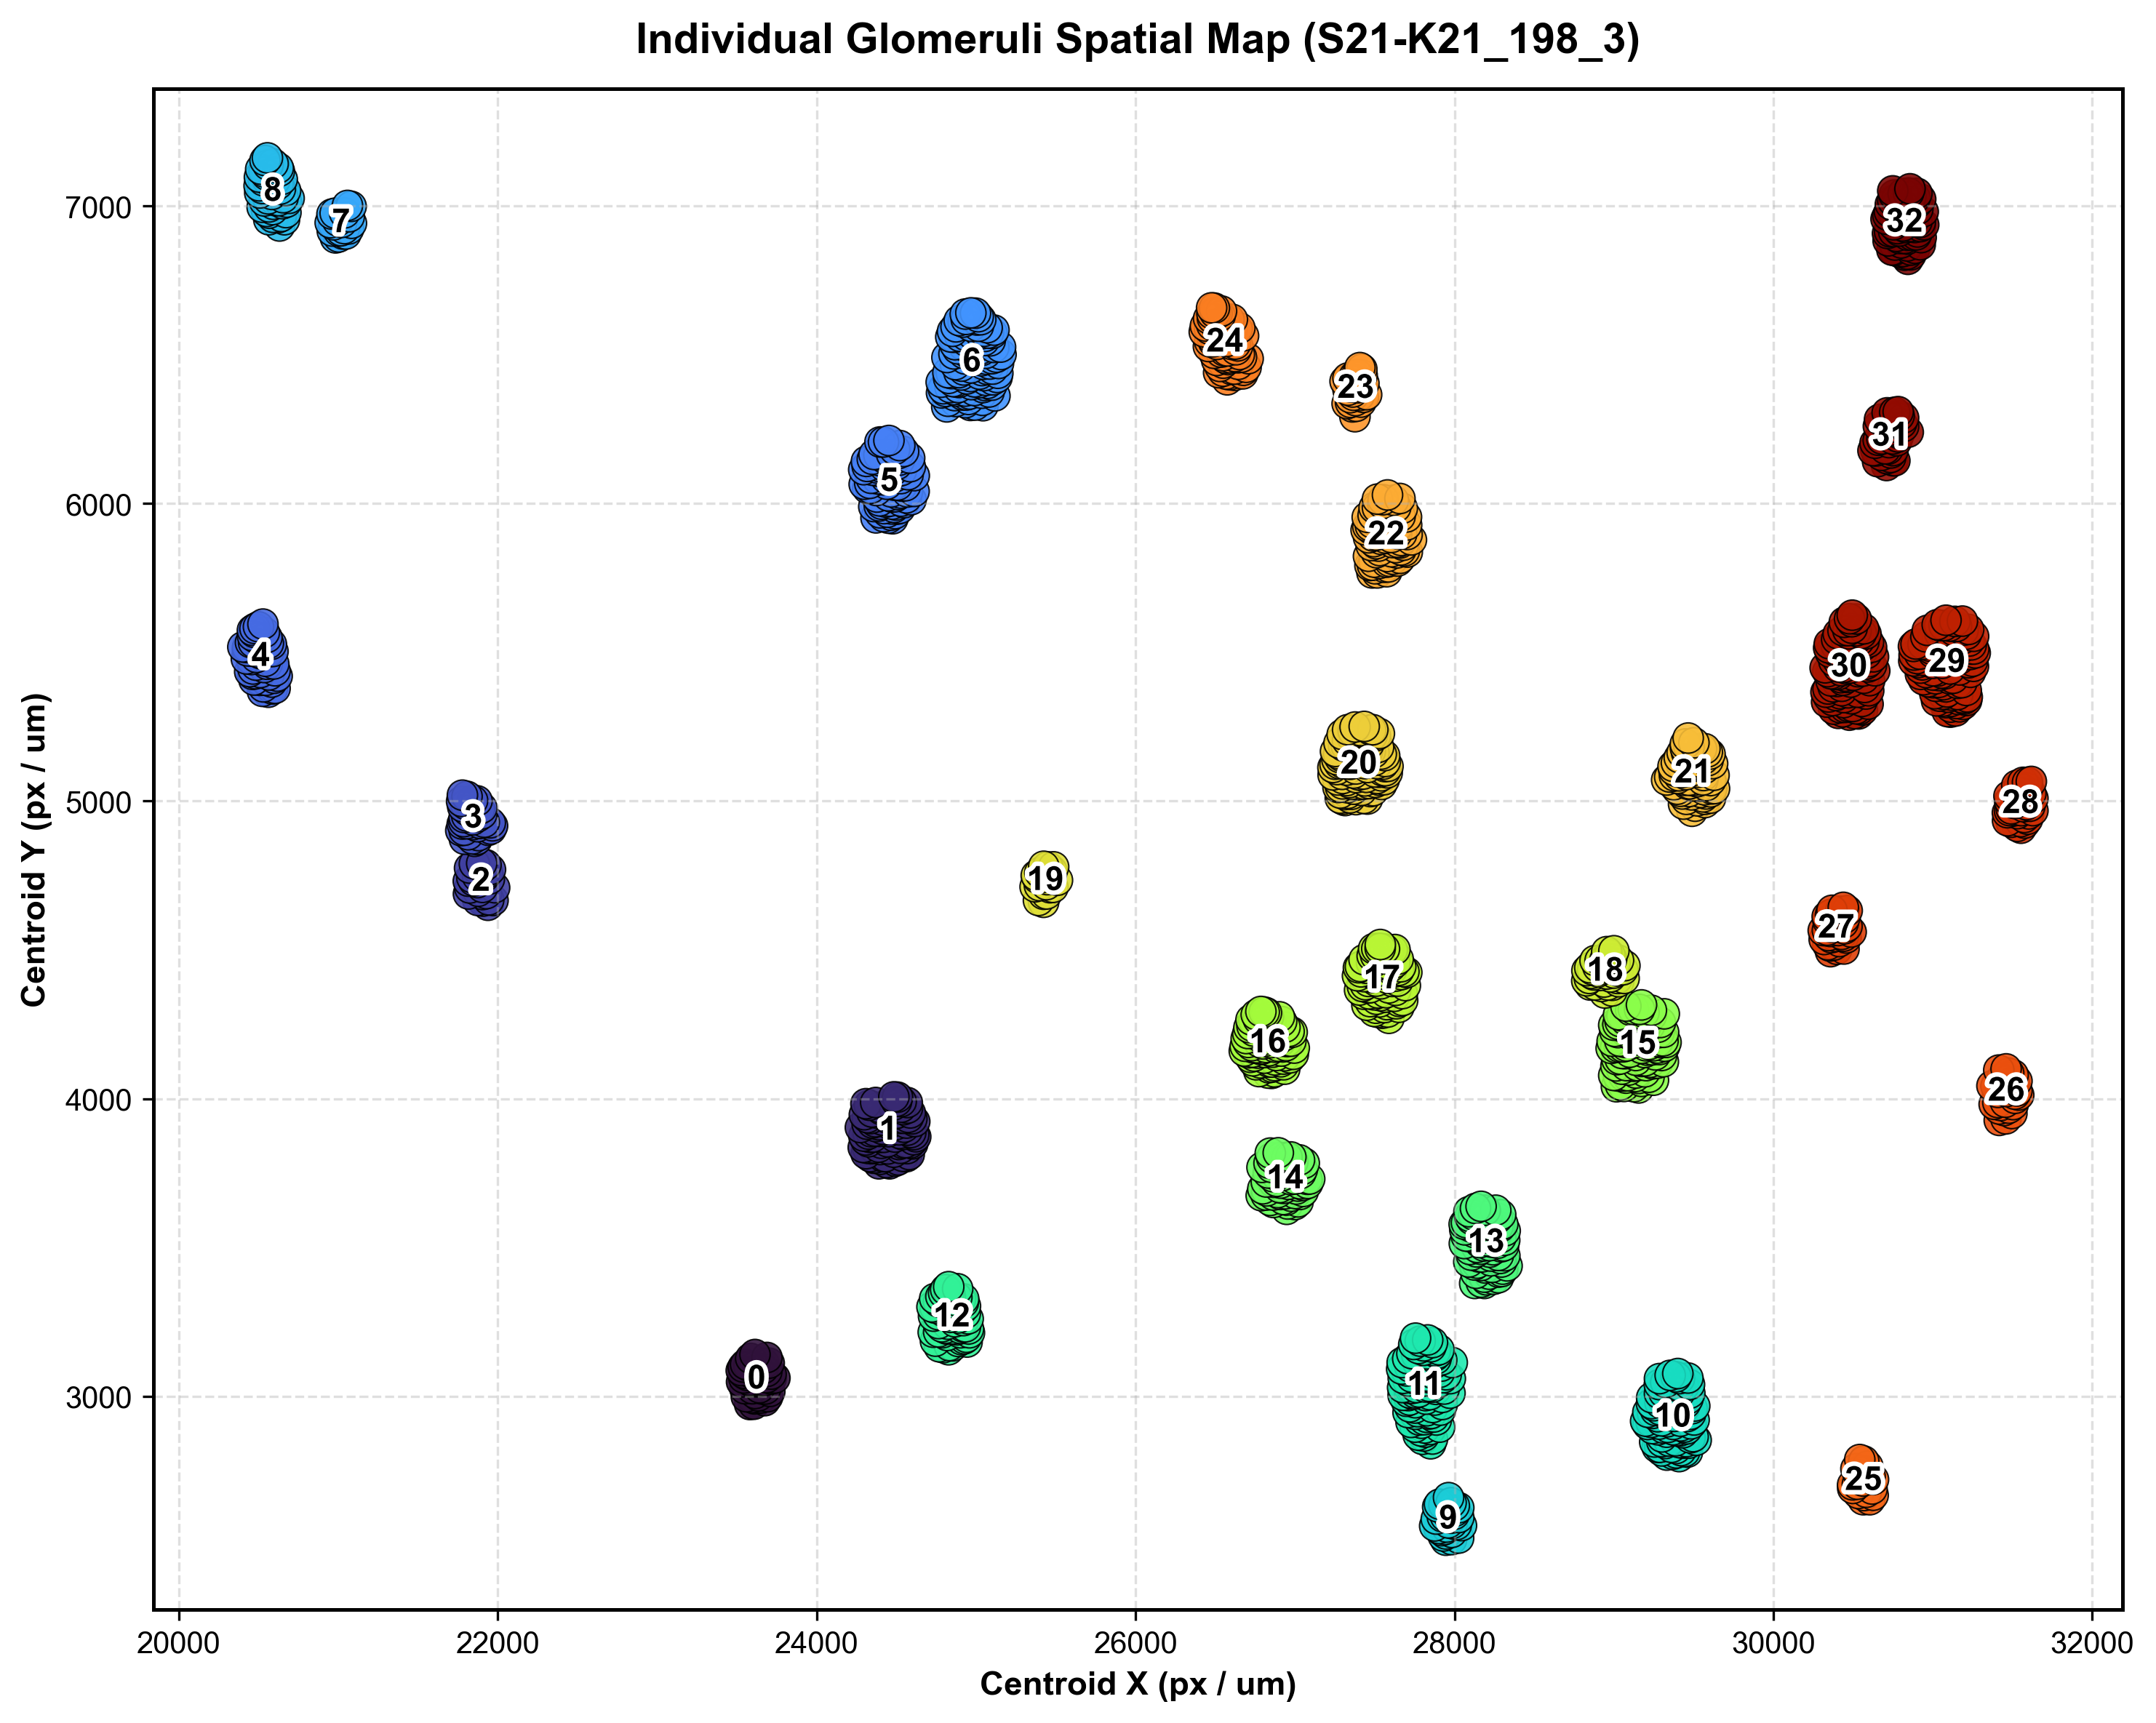

In [5]:
# Step 2: Visualize Identified Individual Glomeruli Spatial Map with Centroid Number Labels
if 'glom' in filtered_df.columns and filtered_df['glom'].notna().any():
    # Select first tissue section or plot overall
    tissue_list = filtered_df[filtered_df['glom'].notna()]['tissue_id'].dropna().unique() if 'tissue_id' in filtered_df.columns else []
    sample_tissue = tissue_list[0] if len(tissue_list) > 0 else None
    
    fig_glom, ax_glom = plot_glomeruli_spatial_clusters(
        df=filtered_df,
        tissue_id=sample_tissue,
        x_col='centroid_x',
        y_col='centroid_y',
        glom_col='glom',
        palette='turbo',
        s=100,
        save_path="./plots/glomeruli_spatial_clusters.png"
    )
    if fig_glom:
        plt.show()

In [ ]:
# Step 3 & 4: Glomerulus-Level Aggregated Correlation Analysis & Ranked Pairwise Relationships
if 'glom' in filtered_df.columns and filtered_df['glom'].notna().any():
    glom_instances = filtered_df[filtered_df['glom'].notna() & (filtered_df['glom'] >= 0)]
    
    # Calculate mean profile per individual glomerulus
    group_averages = glom_instances.groupby('glom')[val_cols].mean().dropna(axis=1, how='all')
    print(f"Aggregated {len(group_averages)} individual glomeruli across {group_averages.shape[1]} features.")
    
    # Define subset of key metabolites for heatmap
    # glom_heatmap_features = [
    #     'CL 72:8 (-H)', 'CL 74:11 (-H)', 'Redox', 'SM 18:1;2O/16:0 (-CH3)', 
    #     'PS 18:0_18:1 (-H)', 'SHexCer 42:1;3O (-H)', 'SHexCer 42:2;3O (-H)', 
    #     'Lipid_to_Protein', 'Lipid_Unsaturation'
    # ]
    glom_heatmap_features = val_cols
    valid_glom_features = [f for f in glom_heatmap_features if f in group_averages.columns]
    if not valid_glom_features:
        valid_glom_features = list(group_averages.columns[:10])
        
    # Compute & Plot Glomeruli Correlation Heatmap
    glom_corr_matrix, fig_gcorr, ax_gcorr = plot_correlation_matrix(
        df=group_averages,
        features=valid_glom_features,
        method='spearman',
        annot=False,
        title="Glomerulus-Averaged Metabolite Correlation Heatmap",
        figsize=(18, 16),
        save_path="./plots/glom_averaged_correlation_heatmap.png"
    )
    plt.show()
    
    # Extract Unstacked Ranked Pairwise Correlations
    avg_corr_matrix = group_averages[valid_glom_features].corr(method='spearman')
    mask = np.triu(np.ones(avg_corr_matrix.shape), k=0).astype(bool)
    unique_corr_matrix = avg_corr_matrix.where(~mask)
    flat_corr_df = unique_corr_matrix.unstack().reset_index()
    flat_corr_df.columns = ["Metabolite_1", "Metabolite_2", "Correlation"]
    flat_corr_df = flat_corr_df.dropna().reset_index(drop=True)
    flat_corr_df["Abs_Corr"] = flat_corr_df["Correlation"].abs()
    flat_corr_df = flat_corr_df.sort_values(by="Abs_Corr", ascending=False).drop(columns=["Abs_Corr"])
    
    os.makedirs("./plots/glom_results", exist_ok=True)
    flat_corr_df.to_csv("./plots/glom_results/group_average_correlations.csv", index=False)
    group_averages.to_csv("./plots/glom_results/individual_glom_averages.csv")
    
    print("Top Pairwise Inter-Glomerular Correlations:")
    display(flat_corr_df.head(20))

In [ ]:
# Step 5: Regional Glomerular Comparison (Inner Cortex vs. Outer Cortex Glomeruli)
glom_data = filtered_df[filtered_df['mask_name'] == 'Cluster1'] if 'mask_name' in filtered_df.columns else filtered_df

feature_subset = [
    'CL 72:8 (-H)', 'CL 74:11 (-H)', 'Redox', 'SM 18:1;2O/16:0 (-CH3)', 
    'PS 18:0_18:1 (-H)', 'SHexCer 42:1;3O (-H)', 'SHexCer 42:2;3O (-H)', 
    'Lipid_to_Protein', 'Lipid_Unsaturation'
]
valid_features = [f for f in feature_subset if f in glom_data.columns]

# P-values dictionary from Games-Howell / Welch's ANOVA testing
pval_map = {
    'CL 72:8 (-H)': 0.0001, 
    'CL 74:11 (-H)': 0.0209,
    'Redox': 0.00005, 
    'SM 18:1;2O/16:0 (-CH3)': 0.00028,
    'PS 18:0_18:1 (-H)': 0.00001,
    'SHexCer 42:1;3O (-H)': 0.000128, 
    'SHexCer 42:2;3O (-H)': 0.018, 
    'Lipid_to_Protein': 0.06,
    'Lipid_Unsaturation': 0.02 
}

display_labels = {
    'CL 72:8 (-H)': 'CL 72:8',
    'CL 74:11 (-H)': 'CL 74:11',
    'Redox': 'ORR',
    'SM 18:1;2O/16:0 (-CH3)': 'SM 34:1;2O',
    'PS 18:0_18:1 (-H)': 'PS 36:1',
    'SHexCer 42:1;3O (-H)': 'SHexCer\n42:1;3O',
    'SHexCer 42:2;3O (-H)': 'SHexCer\n42:2;3O',
    'Lipid_to_Protein': 'Lipid/\nProtein',
    'Lipid_Unsaturation': 'Lipid Unsat.'
}

fig_bars, ax_bars = plot_feature_bars(
    df=glom_data,
    features=valid_features,
    group_col='group',
    groups=['Inner Cortex', 'Outer Cortex'],
    pvals=pval_map,
    feature_display_names=display_labels,
    colors=['#c75b5b', '#911c1c'],
    yerr='std',
    save_path="./plots/glom_regional_paired_bars.png"
)
plt.show()

In [ ]:
# Step 6: Compact Inset Bar Plots for Inner and Outer Cortex Glomeruli Overlays
inset_features = [
    'CL 72:8 (-H)', 'CL 74:11 (-H)', 'Redox', 'SM 18:1;2O/16:0 (-CH3)', 
    'PS 18:0_18:1 (-H)', 'SHexCer 42:1;3O (-H)', 'SHexCer 42:2;3O (-H)'
]
valid_inset_feats = [f for f in inset_features if f in glom_data.columns]

# 1. Inner Cortex Glomeruli Inset
plot_compact_inset(
    df=glom_data,
    features=valid_inset_feats,
    group_name='Inner Cortex',
    group_col='group',
    ylim=(-2, 5),
    yticks=[-2, 0, 2, 4],
    save_filename="./plots/inner_cortex_gloms_inset.png"
)

# 2. Outer Cortex Glomeruli Inset
plot_compact_inset(
    df=glom_data,
    features=valid_inset_feats,
    group_name='Outer Cortex',
    group_col='group',
    ylim=(-2, 5),
    yticks=[-2, 0, 2, 4],
    save_filename="./plots/outer_cortex_gloms_inset.png"
)
plt.show()

## 4. General Tool 1: Statistical Group Comparisons (Box/Violin + Strip Plots)
Runs Welch's ANOVA and Games-Howell post-hoc tests with automatic significance brackets, mean value callouts, and strip plots across all functional units / clusters.

In [ ]:
# Run statistical comparison across cortical / medullary zones for Glomeruli (Cluster1) or PT (Cluster2)
comparison_metrics = val_cols[:15]  # Select top metrics or provide custom list
available_metrics = [m for m in comparison_metrics if m in filtered_df.columns]

anova_results, posthoc_results = plot_group_comparisons(
    df=filtered_df[filtered_df['mask_name'] == 'Cluster1'] if 'mask_name' in filtered_df.columns else filtered_df,
    value_cols=available_metrics,
    group_cols=['group'],
    col_order={'group': ['Outer Cortex', 'Inner Cortex']},
    add_brackets=True,
    palette=['#c75b5b', '#911c1c'],
    output_dir="./plots/glom_regional_comparisons"
)

# Display Top Significant Comparisons
if not posthoc_results.empty:
    print("Significant Pairwise Post-Hoc Differences:")
    display(posthoc_results[posthoc_results['pval'] < 0.05][['item', 'A', 'B', 'mean(A)', 'mean(B)', 'diff', 'pval_formatted']])

## 5. General Tool 2: Correlation Matrix Heatmaps & Target Metric Ranking
Computes pairwise metabolite correlations across functional units and ranks markers correlating with fibrosis/collagen or oxidative stress.

In [ ]:
# Ranked Feature Correlations against Target Metric (e.g. Redox or Collagen_Thickness)
target_metric = 'Redox' if 'Redox' in filtered_df.columns else val_cols[0]
corr_ranking_df, fig_rank, ax_rank = plot_target_correlations(
    df=filtered_df,
    target_metric=target_metric,
    method='spearman',
    top_n=16,
    title=f"Top Features Correlating with {target_metric}",
    save_path=f"./plots/{target_metric}_correlations_ranking.png"
)
plt.show()

## 6. General Tool 3: Spatial Coordinate Mapping & Instance Distributions
Visualizes tissue instance centroid coordinates across tissue sections and plots compositional distributions across anatomical regions.

In [ ]:
# 1. Spatial Tissue Coordinate Mapping
if 'centroid_x' in filtered_df.columns and 'centroid_y' in filtered_df.columns:
    plot_spatial_coordinates(
        df=filtered_df,
        x_col='centroid_x',
        y_col='centroid_y',
        hue_col='FTU' if 'FTU' in filtered_df.columns else 'group',
        title="Spatial Instance Centroid Distribution",
        s=12,
        save_path="./plots/spatial_instance_distribution.png"
    )
    plt.show()

# 2. Compositional Breakdown Across Cortical Zones
if 'FTU' in filtered_df.columns and 'group' in filtered_df.columns:
    plot_category_distribution(
        df=filtered_df,
        cat_col='FTU',
        group_col='group',
        normalize=True,
        save_path="./plots/ftu_composition_per_group.png"
    )
    plt.show()

## 7. General Tool 4: High-Dimensional UMAP Projections
Renders UMAP coordinates color-coded by categorical functional unit / cluster annotations or continuous metabolite intensities.

In [5]:
import umap

reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
z_df[val_cols] = z_df[val_cols].fillna(z_df.groupby(['group', 'unit', 'tissue_id'])[val_cols].transform('median'))
z_df[val_cols] = z_df[val_cols].fillna(z_df.groupby(['group', 'unit'])[val_cols].transform('median'))
cols_with_nan = z_df[val_cols].columns[z_df[val_cols].isna().any()]
keep_vals = [col for col in val_cols if col not in cols_with_nan]
embedding = reducer.fit_transform(z_df[keep_vals])

z_df['umap_1'] = embedding[:, 0]
z_df['umap_2'] = embedding[:, 1]

c:\Users\jvill\miniconda3\envs\hsi_machine_learning\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\jvill\miniconda3\envs\hsi_machine_learning\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [12]:
z_df.to_csv(r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\journal_figures\umap-dropnan_in_im.csv", index=False)

In [13]:
z_df = pd.read_csv(r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\journal_figures\umap-dropnan_in_im.csv")

In [7]:
# Check if precomputed UMAP columns exist or load precomputed embeddings
umap_cols = [c for c in ['umap_1', 'umap_2', 'UMAP_1', 'UMAP_2'] if c in z_df.columns]


UNIT_COLORS = {
    'Glomeruli | Podo, CD31': "#eb2d13",
    'PT | LRP2': "#0a8416",
    # "Cluster3": "#10c922",
    'PT | THY1': "#13eb28",
    'PT | PROM1/VCAM1': "#7af487",
    'TDL | AQP1, Cyto8': "#84530a",
    # "Cluster7": "#f4c37a",
    'TAL | NaK/UMOD': "#840a62",
    'TAL | UMOD': "#f47ad2",
    # "Cluster10": "#f47ad2",
    'DCT | SLC12a3': "#ebd613",
    'DN | Cyto8': "#0a3b84",
    # "Cluster13": "#0e52b7",
    # "Cluster14": "#0e52b7",
    'DN | Cyto8, Bcat': "#1369eb",
    'DN | Cyto8, Bcat, Ecad': "#478af0",
    'DN | Cyto8, Ecad': "#7aabf4",
    'Endothelium | CD31': "#0a8484",
    'Endothelium | CD31, Podo': "#10c9c9",
    'Pericytes | CD90, CD31(-)': "#35eeee",
    'VSMCs | aSMA': "#7af4f4",
    'Immune | CD20': "#8b3103",
    'Immune - MP | CD45, CD206': "#d44a05",
    "Immune - T | CD3, CD4": "#f9702a",
    "Immune - T | CD3, CD8": "#fba173",
    "Interstitial cells | IGFBP7": "#9913eb"
}


if len(umap_cols) >= 2:
    u1, u2 = umap_cols[0], umap_cols[1]
    
    z_df = z_df.sample(frac=1, random_state=42)
    # Categorical Projection by FTU / Cluster
    plot_umap_embedding(
        df=z_df,
        umap_1_col=u1,
        umap_2_col=u2,
        hue_col='unit',
        palette=UNIT_COLORS,
        title="UMAP: Functional Units & Clusters",
        save_path="./plots/umap_categorical_projection.png",
        s=1,
        figsize=(14,14)
    )
    plt.show()
    
    # # Continuous Metabolic Gradient (e.g. Redox / ORR)
    # if 'Redox' in z_df.columns:
    #     plot_umap_embedding(
    #         df=z_df,
    #         umap_1_col=u1,
    #         umap_2_col=u2,
    #         hue_col='Lipid_to_Protein',
    #         is_continuous=True,
    #         cmap='magma',
    #         title="UMAP: Lipid Mean",
    #         save_path="./plots/umap_redox_gradient.png"
    #     )
    #     plt.show()

    plot_umap_embedding(
        df=z_df,
        umap_1_col=u1,
        umap_2_col=u2,
        hue_col='group',
        palette='husl',
        title="UMAP: Regions",
        save_path="./plots/umap_regional_projection.png",
        s=1,
        figsize=(14,14)
    )
    plt.show()


else:
    print("Note: To generate new UMAP embeddings from raw features, use sk_classifier/umap_analysis.py generate_ion_umaps().")

Note: To generate new UMAP embeddings from raw features, use sk_classifier/umap_analysis.py generate_ion_umaps().


In [8]:
# Maps canonical unit names and cluster IDs directly to consistent hex colors
UNIT_COLORS = {UNIT_CLUSTERS.get(c, c): color for c, color in CLUSTER_COLORS.items()}
for c, color in CLUSTER_COLORS.items():
    UNIT_COLORS[c] = color

# Consistent palette for cortical/medullary zones
REGION_COLORS = {
    'Outer Cortex': '#4e79a7',
    'Inner Cortex': '#f28e2b',
    'Outer Stripe': '#59a14f',
    'Inner Stripe': '#edc948',
    'Inner Medulla': '#b07aa1'
}
GROUP_COLORS = REGION_COLORS

# Check if precomputed UMAP columns exist or load precomputed embeddings
umap_cols = [c for c in ['umap_1', 'umap_2', 'UMAP_1', 'UMAP_2'] if c in z_df.columns]

if len(umap_cols) >= 2:
    u1, u2 = umap_cols[0], umap_cols[1]
    
    # Shuffle instances for unbiased visual distribution of overlapping categories
    umap_plot_df = z_df.sample(frac=1, random_state=42).copy()
    
    # =========================================================================
    # 1. Categorical UMAP: Functional Units & Clusters (Consistent 8x8, Small s)
    # =========================================================================
    cluster_order = [c for c in CLUSTER_COLORS.keys() if c in umap_plot_df['mask_name'].values]
    if not cluster_order:
        cluster_order = sorted(umap_plot_df['mask_name'].dropna().unique())
        
    # Map cluster identifiers to full canonical unit display names
    cluster_labels = [f"{c}: {UNIT_CLUSTERS.get(c, c)}" for c in cluster_order]
    cluster_color_map = {f"{c}: {UNIT_CLUSTERS.get(c, c)}": CLUSTER_COLORS.get(c, '#808080') for c in cluster_order}
    
    # Add mapped display column for clear unit naming
    umap_plot_df['cluster_display'] = umap_plot_df['mask_name'].map(
        lambda c: f"{c}: {UNIT_CLUSTERS.get(c, c)}" if c in UNIT_CLUSTERS else c
    )
    
    fig_cat, ax_cat = plot_umap_embedding(
        df=umap_plot_df,
        umap_1_col=u1,
        umap_2_col=u2,
        hue_col='cluster_display',
        hue_order=cluster_labels,
        palette=cluster_color_map,
        title="UMAP: Functional Units & Clusters",
        s=1.5,
        alpha=0.8,
        figsize=(8, 8),
        show_legend=False,
        save_separate_legend=True,
        legend_ncol=2,
        legend_save_path="./plots/umap_clusters_legend.png",
        save_path="./plots/umap_categorical_projection.png"
    )
    plt.show()
    
    # Render separate standalone cluster legend image
    fig_leg_cluster = save_standalone_legend(
        labels=cluster_labels,
        palette=cluster_color_map,
        title="Functional Units & Clusters",
        save_path="./plots/umap_clusters_legend.png",
        ncol=2,
        fontsize=11,
        title_fontsize=13,
        markersize=10
    )
    plt.show()
    
    # =========================================================================
    # 2. Categorical UMAP: Anatomical Regions (Consistent 8x8, Small s)
    # =========================================================================
    region_order = [g for g in GROUP_ORDER if g in umap_plot_df['group'].values]
    if not region_order:
        region_order = list(umap_plot_df['group'].dropna().unique())
        
    fig_reg, ax_reg = plot_umap_embedding(
        df=umap_plot_df,
        umap_1_col=u1,
        umap_2_col=u2,
        hue_col='group',
        hue_order=region_order,
        palette=REGION_COLORS,
        title="UMAP: Anatomical Regions",
        s=1.5,
        alpha=0.8,
        figsize=(8, 8),
        show_legend=False,
        save_separate_legend=True,
        legend_ncol=1,
        legend_save_path="./plots/umap_regions_legend.png",
        save_path="./plots/umap_regional_projection.png"
    )
    plt.show()
    
    # Render separate standalone region legend image
    fig_leg_region = save_standalone_legend(
        labels=region_order,
        palette=REGION_COLORS,
        title="Anatomical Regions",
        save_path="./plots/umap_regions_legend.png",
        ncol=1,
        fontsize=11,
        title_fontsize=13,
        markersize=10
    )
    plt.show()


Saved region density overlay UMAP plot to: ./plots/umap_clusters_with_regional_density_overlay.png


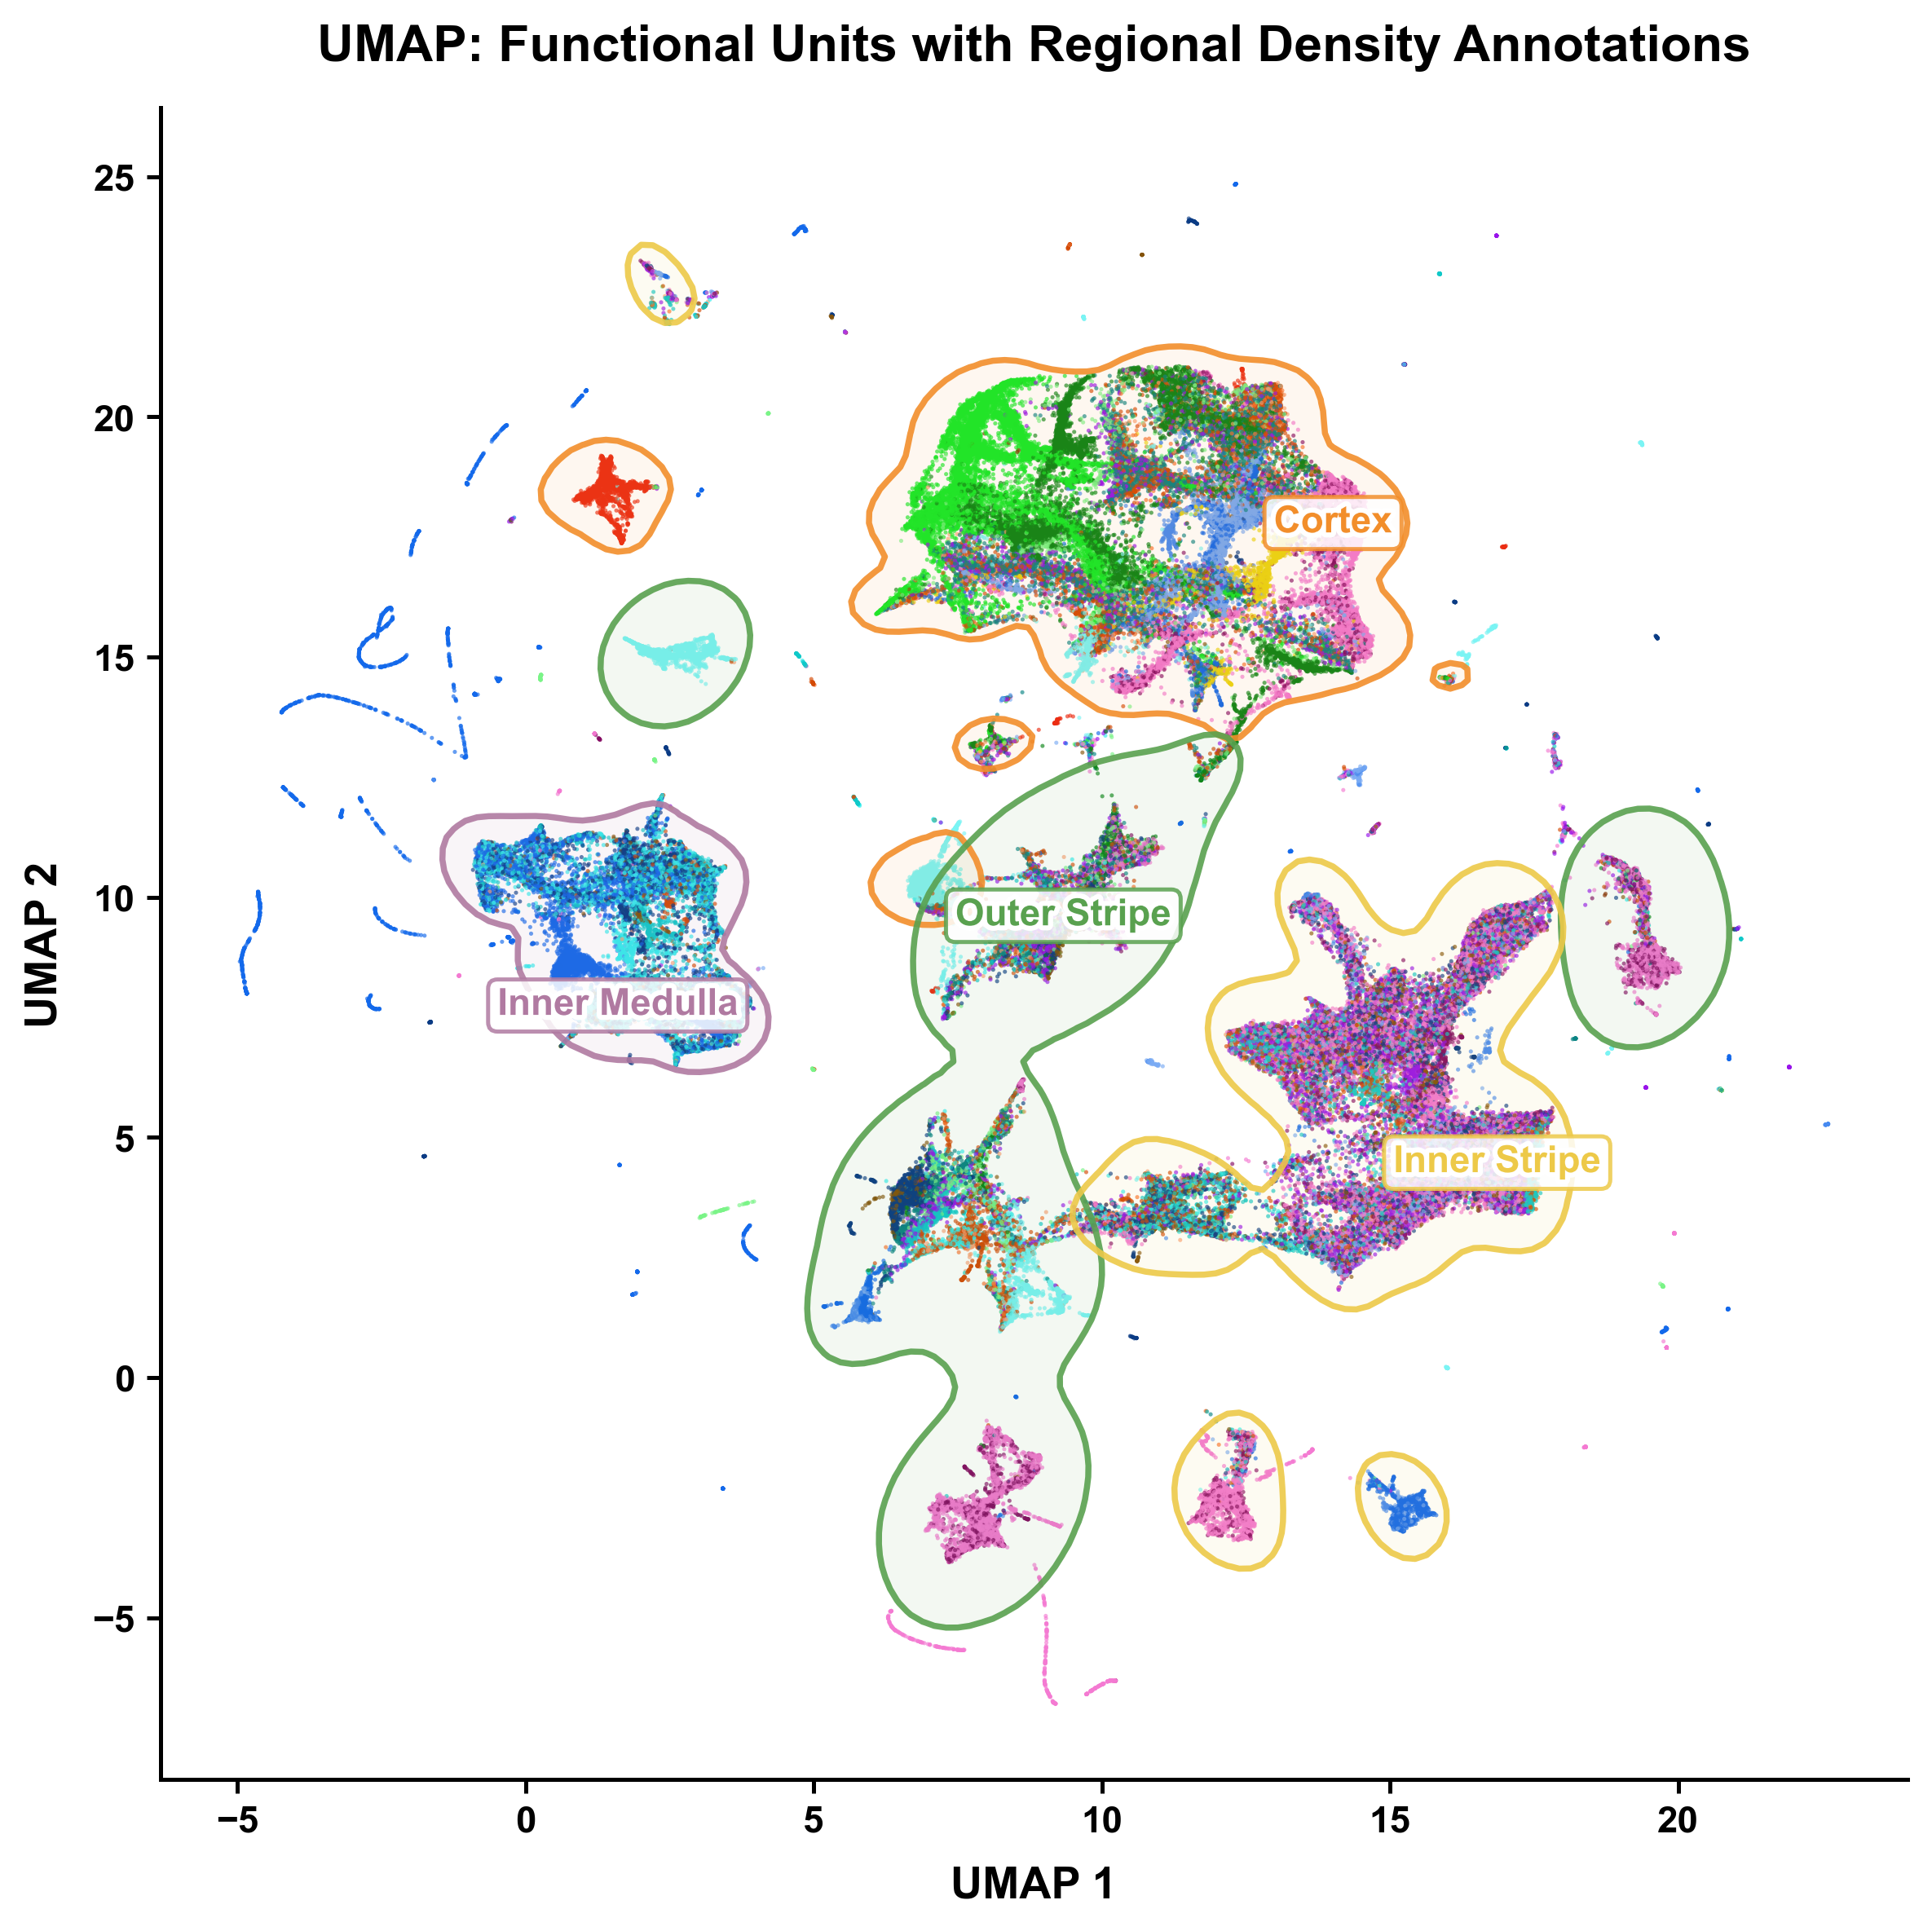

In [ ]:
# Composite UMAP: Regional Density Boundaries Overlaid onto Cluster Points
umap_plot_df = z_df.sample(frac=1, random_state=42).copy()
umap_cols = [c for c in ['umap_1', 'umap_2', 'UMAP_1', 'UMAP_2'] if c in z_df.columns]

if len(umap_cols) >= 2:
    u1, u2 = umap_cols[0], umap_cols[1]

UNIT_COLORS = {
    'Glomeruli | Podo, CD31': "#eb2d13",
    'PT | LRP2': "#0a8416",
    # "Cluster3": "#10c922",
    'PT | THY1': "#13eb28",
    'PT | PROM1/VCAM1': "#7af487",
    'TDL | AQP1, Cyto8': "#84530a",
    # "Cluster7": "#f4c37a",
    'TAL | NaK/UMOD': "#840a62",
    'TAL | UMOD': "#f47ad2",
    # "Cluster10": "#f47ad2",
    'DCT | SLC12a3': "#ebd613",
    'DN | Cyto8': "#0a3b84",
    # "Cluster13": "#0e52b7",
    # "Cluster14": "#0e52b7",
    'DN | Cyto8, Bcat': "#1369eb",
    'DN | Cyto8, Bcat, Ecad': "#478af0",
    'DN | Cyto8, Ecad': "#7aabf4",
    'Endothelium | CD31': "#0a8484",
    'Endothelium | CD31, Podo': "#10c9c9",
    'Pericytes | CD90, CD31(-)': "#35eeee",
    'VSMCs | aSMA': "#7af4f4",
    'Immune | CD20': "#8b3103",
    'Immune - MP | CD45, CD206': "#d44a05",
    "Immune - T | CD3, CD4": "#f9702a",
    "Immune - T | CD3, CD8": "#fba173",
    "Interstitial cells | IGFBP7": "#9913eb"
}


unit_order = [c for c in UNIT_COLORS.keys() if c in umap_plot_df['unit'].values]
if not unit_order:
    unit_order = sorted(umap_plot_df['unit'].dropna().unique())

umap_plot_df['group'] = umap_plot_df['group'].replace({'Outer Cortex': 'Cortex', 'Inner Cortex': 'Cortex'})

unit_labels = list(UNIT_COLORS.keys())
# Consistent palette for cortical/medullary zones
REGION_COLORS = {
    # 'Outer Cortex': '#4e79a7',
    'Cortex': '#f28e2b',
    'Outer Stripe': '#59a14f',
    'Inner Stripe': '#edc948',
    'Inner Medulla': '#b07aa1'
}
GROUP_COLORS = REGION_COLORS

GROUP_ORDER = list(REGION_COLORS.keys())

region_order = [g for g in GROUP_ORDER if g in umap_plot_df['group'].values]
if not region_order:
    region_order = list(umap_plot_df['group'].dropna().unique())



fig_overlay, ax_overlay = plot_umap_with_region_density_overlay(
    df=umap_plot_df,
    umap_1_col=u1,
    umap_2_col=u2,
    cluster_col='unit',
    cluster_palette=UNIT_COLORS,
    cluster_order=unit_labels,
    region_col='group',
    region_palette=REGION_COLORS,
    region_order=region_order,
    density_levels=[0.1],   # Outer envelope and highest density core
    contour_alpha=0.9,
    contour_lw=1.8,
    contour_fill=True,
    fill_alpha=0.07,
    annotate_region_labels=True,   # Places bold label badge at density peak
    show_region_legend=True,
    region_legend_title="Regions",
    region_legend_loc="lower left",
    label_fontsize=11,
    s=1,
    alpha=0.65,
    figsize=(8, 8),
    title="UMAP: Functional Units with Regional Density Annotations",
    save_path="./plots/umap_clusters_with_regional_density_overlay.png"
)
plt.show()


In [28]:
umap_plot_df['group'].unique()

array(['Inner Stripe', 'Outer Stripe', 'Cortex', 'Inner Medulla'],
      dtype=object)

In [29]:
region_order

['Outer Stripe', 'Inner Stripe', 'Inner Medulla']

## 8. Session Summary & Audit Trail
Review all datasets loaded, transformed, and visualized in the current session.

In [ ]:
print("Session Dataset Audit Trail:")
display_dataset_log()